# Week 6 · Day 1 — Probability and distributions: HW 6.1 starter

Nur Finance · as of 2026-10-01. Part 0 is a walk-through (run and read). Then **eight functions**, each followed by an
**assert cell**; a red cell is a function you have not written yet. HW 6.1 is done when every assert cell runs silently.
Use `scipy.stats` and `numpy`; every simulation uses the seeded `rng` (or `np.random.default_rng(seed)`).

In [1]:
from pathlib import Path
import hashlib
import sqlite3
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
DATA = Path("../..")           # this notebook lives in data/python/week6/, so "../.." is the data/ folder
AS_OF = pd.Timestamp("2026-10-01")
con = sqlite3.connect(DATA / "raw" / "nur.db")
rng = np.random.default_rng(2026)   # one seeded generator: the same "random" numbers on every run


def check(value, fingerprints, dp=0):
    """Right or wrong without showing the answer: the rounded value's fingerprint must be one of the expected ones."""
    fp = hashlib.sha256(f"nur-w6:{round(float(value), dp):.{dp}f}".encode()).hexdigest()[:12]
    assert fp in fingerprints, "not yet: this result is not the expected one — check your function and run again"

## 0. Walk-through — Nilufar's 400 loans
FPD30 on the whole book is 91 of 7 099 first instalments (week 2, week 5). Treat each of next month's 400 loans as a coin that
lands "default" with probability p = 91/7 099. The number of defaults is then **binomial**, X ~ Bin(400, p).

In [2]:
P_FPD = 91 / 7099
N = 400
X = stats.binom(N, P_FPD)
print(f"p = {P_FPD:.4%} · E[X] = {X.mean():.2f} · sd = {X.std():.2f}")
table = pd.DataFrame({"k": range(0, 15)})
table["P(X = k)"] = X.pmf(table["k"]).round(4)
table["P(X >= k)"] = X.sf(table["k"] - 1).round(4)     # sf(k-1) = P(X > k-1) = P(X >= k)
table

p = 1.2819% · E[X] = 5.13 · sd = 2.25


,k,P(X = k),P(X >= k)
0,0,0.0057,1.0000
1,1,0.0298,0.9943
2,2,0.0772,0.9645
3,3,0.1330,0.8872
4,4,0.1714,0.7542
5,5,0.1763,0.5828
6,6,0.1507,0.4065
7,7,0.1101,0.2558
8,8,0.0703,0.1457
9,9,0.0397,0.0754


In [3]:
# The same question by brute force: 100 000 imaginary months of 400 loans
months = rng.binomial(N, P_FPD, size=100_000)
print(f"simulated mean {months.mean():.3f} · sd {months.std():.3f} · P(X >= 10) {np.mean(months >= 10):.4f} (formula {X.sf(9):.4f})")
print("middle 95 % of months:", np.quantile(months, [0.025, 0.975]))

simulated mean 5.115 · sd 2.250 · P(X >= 10) 0.0355 (formula 0.0357)
middle 95 % of months: [ 1. 10.]


## 0b. Is the credit score normal? Histogram + QQ plot of 13 612 applicants' scores (388 have no score)

n 13612 · missing 388 · mean 659.6 · sd 59.5


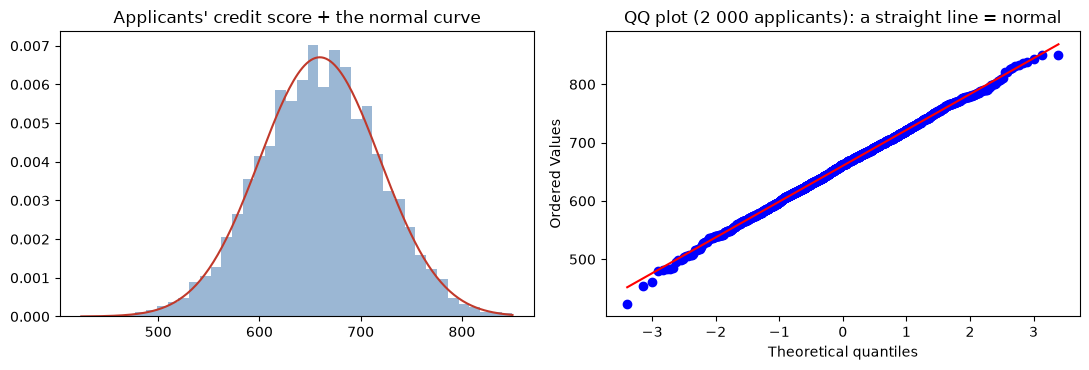

within ±1 sd: 68.0%
within ±2 sd: 95.4%
within ±3 sd: 99.8%


In [4]:
apps = pd.read_sql("SELECT application_id, channel, applied_at, credit_score, status FROM applications", con, parse_dates=["applied_at"])
s = apps["credit_score"].dropna()
mu, sd = s.mean(), s.std()
print(f"n {len(s)} · missing {apps.credit_score.isna().sum()} · mean {mu:.1f} · sd {sd:.1f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(s, bins=40, density=True, color="#9bb7d4")
grid = np.linspace(s.min(), s.max(), 200)
ax[0].plot(grid, stats.norm.pdf(grid, mu, sd), color="#c0392b")
ax[0].set_title("Applicants' credit score + the normal curve")
stats.probplot(s.sample(2000, random_state=2026), dist="norm", plot=ax[1])
ax[1].set_title("QQ plot (2 000 applicants): a straight line = normal")
plt.tight_layout(); plt.show()
for k in (1, 2, 3):
    print(f"within ±{k} sd: {np.mean(np.abs(s - mu) <= k * sd):.1%}")

## 0c. Applications per hour — Poisson? (2026-01-01 … 2026-09-30, clock hours 08:00–20:59, empty hours included)

In [5]:
a = apps[(apps.applied_at >= "2026-01-01") & (apps.applied_at < "2026-10-01")].copy()
a = a[a.applied_at.dt.hour.between(8, 20)]
days = pd.date_range("2026-01-01", "2026-09-30")
slots = pd.MultiIndex.from_product([days, range(8, 21)], names=["day", "hour"])
per_hour = a.groupby([a.applied_at.dt.normalize(), a.applied_at.dt.hour]).size().reindex(slots, fill_value=0)
lam = per_hour.mean()
print(f"{len(a)} applications in {len(slots)} clock hours: lambda = {lam:.4f} per hour; variance {per_hour.var():.4f}")
obs = per_hour.value_counts().sort_index()
pd.DataFrame({"hours observed": obs, "Poisson expects": (len(slots) * stats.poisson.pmf(obs.index, lam)).round(1)})

5102 applications in 3549 clock hours: lambda = 1.4376 per hour; variance 1.4401


,hours observed,Poisson expects
0,850,842.9
1,1204,1211.7
2,863,871.0
3,420,417.4
4,163,150.0
5,38,43.1
6,8,10.3
7,2,2.1
8,1,0.4


## 1. `prob_exactly(k, n, p)` — P(X = k) for X ~ Bin(n, p)

In [6]:
def prob_exactly(k, n, p):
    """Probability of exactly k defaults among n loans, each defaulting with probability p."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [7]:
check(prob_exactly(5, 400, 91 / 7099), ['132faf0b2db2', 'c5aadcf6c00a', 'df96082462f5'], 4)
check(prob_exactly(0, 400, 91 / 7099), ['6fef3fb21663', '7def3b7cfbc2', 'c82f75e0f82f'], 4)
print("prob_exactly OK")

NotImplementedError: TODO: write me, then run the assert cell below

## 2. `prob_at_least(k, n, p)` — P(X ≥ k). Careful: P(X ≥ k) = 1 − P(X ≤ k − 1)

In [8]:
def prob_at_least(k, n, p):
    """Probability of k or more defaults among n loans."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [9]:
check(prob_at_least(10, 400, 91 / 7099), ['81773ec33918', 'b9ed9749a9c8', 'dd57c953274e'], 4)
check(prob_at_least(12, 400, 91 / 7099), ['48ae76a099a5', 'acc5e06fa6f7', 'c727cfd55057'], 4)
assert prob_at_least(0, 400, 0.5) == 1
print("prob_at_least OK")

NotImplementedError: TODO: write me, then run the assert cell below

## 3. `panic_threshold(n, p, alpha)` — the smallest k with P(X ≥ k) ≤ alpha
"If the true rate is still p, seeing k or more defaults happens less than alpha of the time" — Nilufar's alarm line.

In [10]:
def panic_threshold(n, p, alpha=0.05):
    """Smallest integer k such that P(X >= k) <= alpha for X ~ Bin(n, p)."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [11]:
check(panic_threshold(400, 91 / 7099, 0.05), ['f96b3cd30ae5'])
check(panic_threshold(400, 91 / 7099, 0.01), ['4b30aa428e85'])
check(panic_threshold(2411, 0.0104, 0.05), ['ff9a78974d28'])      # the app channel's volume at the branch rate
print("panic_threshold OK")

NotImplementedError: TODO: write me, then run the assert cell below

## 4. `expected_loss(book, lgd=0.6)` — Σ PD × LGD × EAD over a small book
`book` is a DataFrame with columns `pd` (probability of default) and `ead` (exposure at default, soum). Return one number.

In [12]:
def expected_loss(book, lgd=0.6):
    """Expected loss of the book in soum: sum over loans of pd * lgd * ead."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [13]:
book = pd.DataFrame({"grade": ["A", "B", "C", "D", "B"],
                     "pd":    [0.0093, 0.0188, 0.0512, 0.1091, 0.0188],
                     "ead":   [50_000_000, 20_000_000, 10_000_000, 5_000_000, 100_000_000]})
check(expected_loss(book), ['e067b61c8278'])
check(expected_loss(book, lgd=1.0), ['75d31e5e0e9c'])
print("expected_loss OK")

NotImplementedError: TODO: write me, then run the assert cell below

## 5. `bayes_posterior(prior, sensitivity, false_positive_rate)` — P(fraud | flag)
A vendor's rule flags 90 % of fraudsters and 5 % of honest applicants. The prior: 44 of 7 099 loans never paid a single soum
of the first instalment (our "first-payment fraud" proxy).

In [14]:
def bayes_posterior(prior, sensitivity, false_positive_rate):
    """P(bad | flagged) by Bayes' rule."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [15]:
check(bayes_posterior(44 / 7099, 0.90, 0.05), ['005d776cc63a', '6994060e9076', 'd3bc1bcd1841'], 4)
check(bayes_posterior(0.5, 0.90, 0.05), ['7ecec0162ed1', '89d6586d58cf', 'e4640077c917'], 4)
print("bayes_posterior OK")

NotImplementedError: TODO: write me, then run the assert cell below

## 6. `simulate_defaults(n, p, months, seed=2026)` — an array of `months` simulated default counts
Use `np.random.default_rng(seed)`. Any correct method is fine (`.binomial`, or `.random((months, n)) < p` summed per row).

In [16]:
def simulate_defaults(n, p, months, seed=2026):
    """numpy array of length `months`: the number of defaults among n loans in each simulated month."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [17]:
sim = simulate_defaults(400, 91 / 7099, 100_000)
assert len(sim) == 100_000
assert abs(sim.mean() - 400 * 91 / 7099) < 0.05            # the formula's mean, n * p
check(np.mean(sim >= 10), ['028b8ac7829d', '0c324676a0c1', '0f591185388e', '1bab0548c848', '1f4e6dd60235', '202b32d088dd', '21e0be13c0e2', '239d6ae8c3be', '2599a9766330', '2793638ece57', '27c918fac1c7', '2ad06467157a', '372f2fd23818', '39f2dc49fb4a', '3f6fa608a63f', '41790ad9ab19', '45052835751a', '46ee7a907177', '534c19abdd48', '57029e177126', '5cc14573dc4d', '5da3da42165a', '6ab6f02a5ef3', '779c993f5f05', '7f5a8546be2c', '80a5fc26a666', '80f463aafb4a', '811960d98d34', '81773ec33918', '826a02dc75bb', '828ab757f455', '8e25fb2afce4', '91162ab494af', '97ccf93051da', '9db17978be64', '9dfd55b65b46', 'a29f7dcd3491', 'a6b28bd3b271', 'a9cd7920402e', 'ae998f54d0dd', 'b1c8b9ba8de5', 'b433da16caca', 'b4c5e43c61c2', 'b9ed9749a9c8', 'bd0948233d98', 'c3b52680e8b7', 'c5381d824239', 'c9bcf36f6d25', 'd0ba3929e800', 'd273e98a3dfd', 'd8024c6760a2', 'dc7149a01630', 'dd57c953274e', 'dfff147c5c85', 'e082ddb552ab', 'e35ea67386f6', 'e49a1fe2391b', 'e8b4ec7239cc', 'f1f02562b4f9', 'f3c0cc67a087', 'ff7d0dde3ae9'], 4)      # close to the formula's P(X >= 10)
assert (simulate_defaults(400, 0.0128, 5, seed=1) == simulate_defaults(400, 0.0128, 5, seed=1)).all()   # seeded = repeatable
print("simulate_defaults OK")

NotImplementedError: TODO: write me, then run the assert cell below

## 7. `hourly_rate(apps)` — lambda for the Poisson: applications per clock hour, 2026-01-01 … 2026-09-30, 08:00–20:59
Count the applications in that window and divide by the number of clock hours (273 days × 13 hours) — empty hours count.

In [18]:
def hourly_rate(apps):
    """Applications per clock hour (08:00-20:59) between 2026-01-01 and 2026-09-30 inclusive."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [19]:
lam7 = hourly_rate(apps)
check(lam7, ['062234c8334b', '137aa5ca140f', '1c0801f62dda', '2b0f6dabc870', '323e67a7cbd3', '3ec4599b4038', '3f22491c1cb5', '4388b5887ca0', '5f034c61a79d', '7187f985a626', '82aafb9dbaf5', '956edf798bf0', 'a69ce949ce60', 'ad477a50edaf', 'bc184925de5e', 'ccc52c979d30', 'd874aabd4ee7', 'd8ccbe82bf45', 'e0e6384de352', 'f09a3206e511', 'fc3811d33c2f'], 4)
check(stats.poisson.sf(4, lam7), ['08dbec098617', '2055052e71f4', '2d0c0c6e6c1e', '3dbbc7799951', '5eccbe97bd7a', '60e94135738e', '6932b469c37c', '7c6768f34b38', '7d33bec04e5b', '856f92297655', '89dc0953200c', '9902d0a5b2ac', '9cfc04d896a9', 'a08cf7a891a3', 'b339c64bf1f1', 'b4c40e7c1bb6', 'bab7bdcdee72', 'c76da9df4752', 'd14e89e2b800', 'db5a12742829', 'f0801c4211b0'], 4)        # P(5 or more in one hour)
print("hourly_rate OK", round(lam7, 4))

NotImplementedError: TODO: write me, then run the assert cell below

## 8. `share_between(a, b, mu, sigma)` — P(a ≤ score < b) under a normal model

In [20]:
def share_between(a, b, mu, sigma):
    """P(a <= X < b) for X ~ Normal(mu, sigma)."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [21]:
s = apps["credit_score"].dropna()
model = share_between(600, 700, s.mean(), s.std())
actual = ((s >= 600) & (s < 700)).mean()
check(model, ['0cb0615e17ef', '123593c8371e', '1de48f0626f6', '2d460783e806', '3266a0e23d2c', '5c0fbcaa1590', '5d236dc551d2', '5dde6cb73522', '66a6b42de925', '769cfa18890a', '7db001967f97', '7dbdbaa00d1d', '7e5882b0ec2f', '830beab05aba', '84fd1244fd77', '94355dea90a6', '9ba3d8d98e49', '9bf56397cb9c', 'e6af0c9f9336', 'ee16b25ccc90', 'f3b245704356'], 4)
assert abs(model - actual) < 0.01                             # the model is within a point of reality
print(f"share_between OK: model {model:.4f} · actual {actual:.4f}")

NotImplementedError: TODO: write me, then run the assert cell below

## Your answer to Nilufar (three sentences, Markdown)
Expected FPDs next month, the range that is normal, and the number at which she should pick up the phone — with the probability behind it.

…